# Gamma Distribution

Companion notebook for the [gamma distribution note](../../notes/random_variables_and_distributions/continuous/gamma_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/gamma_distribution.md).

$X\sim\text{Gamma}(\alpha,\beta)$ with shape $\alpha$ and **rate** $\beta$:

$$f(x)=\frac{\beta^\alpha}{\Gamma(\alpha)}x^{\alpha-1}e^{-\beta x},\qquad E[X]=\frac\alpha\beta,\qquad \operatorname{Var}(X)=\frac\alpha{\beta^2}.$$

`scipy.stats.gamma(a, scale)` takes `scale = 1/beta`.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations
from scipy.integrate import cumulative_trapezoid

## Hand-rolled implementation

The gamma CDF has no elementary closed form, so the hand-rolled CDF integrates the PDF numerically with the trapezoid rule on a fine grid.

In [2]:
class GammaDistribution:
    def __init__(self, alpha, beta):
        self.alpha = alpha  # shape
        self.beta = beta    # rate (scipy's scale = 1 / beta)

    def pdf(self, x):
        x = np.asarray(x, dtype=float)
        coef = self.beta**self.alpha / math.gamma(self.alpha)
        return np.where(x >= 0, coef * x ** (self.alpha - 1) * np.exp(-self.beta * x), 0.0)

    def cdf(self, x):
        """Numerical integral of the PDF (no closed form); x must be a sorted grid from 0."""
        x = np.asarray(x, dtype=float)
        return cumulative_trapezoid(self.pdf(x), x, initial=0.0)

## Check against `scipy.stats`

In [3]:
a1, b1 = 2, 2
a2, b2 = 5, 1
x = np.linspace(0, 20, 4001)
d1, d2 = GammaDistribution(a1, b1), GammaDistribution(a2, b2)

pdf1, pdf2 = stats.gamma.pdf(x, a1, scale=1 / b1), stats.gamma.pdf(x, a2, scale=1 / b2)
cdf1, cdf2 = stats.gamma.cdf(x, a1, scale=1 / b1), stats.gamma.cdf(x, a2, scale=1 / b2)
print("PDF matches:", np.allclose(d1.pdf(x), pdf1), np.allclose(d2.pdf(x), pdf2))
print("max CDF error (numerical integral):",
      np.abs(d1.cdf(x) - cdf1).max().round(7), np.abs(d2.cdf(x) - cdf2).max().round(7))

PDF matches: True True
max CDF error (numerical integral): 9.5e-06 2e-07


## Shape of the PDF and CDF

Gamma(2, rate 2) has mean 1 and a sharp peak; Gamma(5, rate 1) has mean 5 and is broader and more symmetric. For $\alpha=1$ the gamma is exponential.

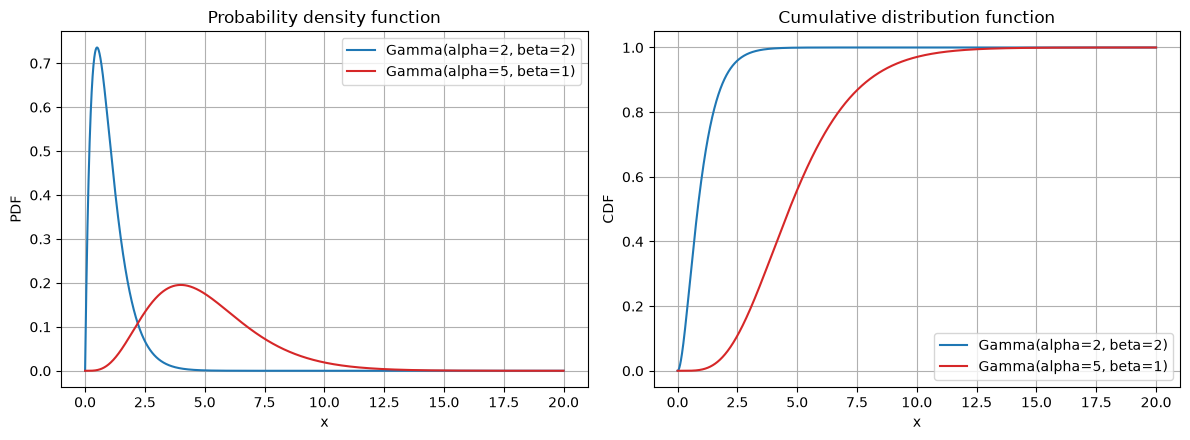

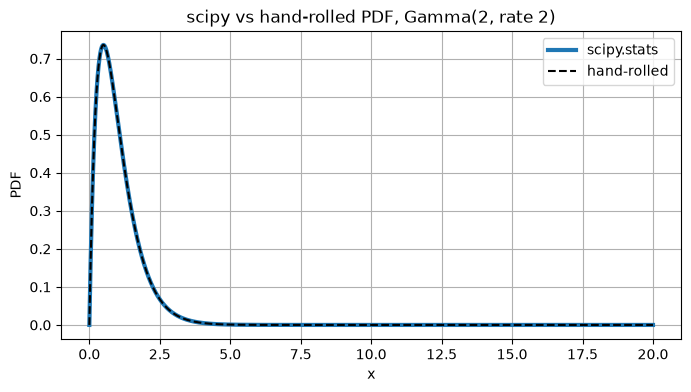

In [4]:
def plot_pdf_cdf(x, pdf1, cdf1, label1, pdf2, cdf2, label2):
    """PDF and CDF of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(x, pdf1, color="C0", label=label1)
    ax1.plot(x, pdf2, color="C3", label=label2)
    ax1.set(xlabel="x", ylabel="PDF", title="Probability density function")
    ax2.plot(x, cdf1, color="C0", label=label1)
    ax2.plot(x, cdf2, color="C3", label=label2)
    ax2.set(xlabel="x", ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, title):
    """Hand-rolled PDF (dashed) on top of the scipy.stats PDF (solid)."""
    plt.figure(figsize=(8, 4))
    plt.plot(x, ref, color="C0", linewidth=3, label="scipy.stats")
    plt.plot(x, custom, "k--", label="hand-rolled")
    plt.xlabel("x")
    plt.ylabel("PDF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pdf_cdf(x, pdf1, cdf1, f"Gamma(alpha={a1}, beta={b1})", pdf2, cdf2, f"Gamma(alpha={a2}, beta={b2})")
plot_overlay(x, pdf1, d1.pdf(x), "scipy vs hand-rolled PDF, Gamma(2, rate 2)")

## Worked example: flood intervals

From the note: $\alpha=2$, $\beta=1/3$ per year. For integer shape, $P(X>x)=e^{-\beta x}\sum_{k<\alpha}(\beta x)^k/k!$ (a Poisson sum), which we verify against the CDF.

In [5]:
alpha, beta = 2, 1 / 3
print(f"mean = {alpha / beta:.1f} years, var = {alpha / beta**2:.1f} years^2")

x0 = 9
poisson_sum = math.exp(-beta * x0) * sum((beta * x0) ** k / math.factorial(k) for k in range(alpha))
print(f"P(X > {x0}) via Poisson sum = {poisson_sum:.5f}")
print(f"P(X > {x0}) via scipy sf    = {stats.gamma.sf(x0, alpha, scale=1 / beta):.5f}")

# A sum of alpha independent Exp(beta) waiting times is Gamma(alpha, beta)
sums = rng.exponential(1 / beta, size=(100_000, alpha)).sum(axis=1)
print(f"simulated P(sum of {alpha} exponentials > {x0}) = {(sums > x0).mean():.4f}")

mean = 6.0 years, var = 18.0 years^2
P(X > 9) via Poisson sum = 0.19915
P(X > 9) via scipy sf    = 0.19915
simulated P(sum of 2 exponentials > 9) = 0.1993


## Simulation versus theory

mean: sample 4.9973  theory 5.0000
var : sample 4.9729  theory 5.0000


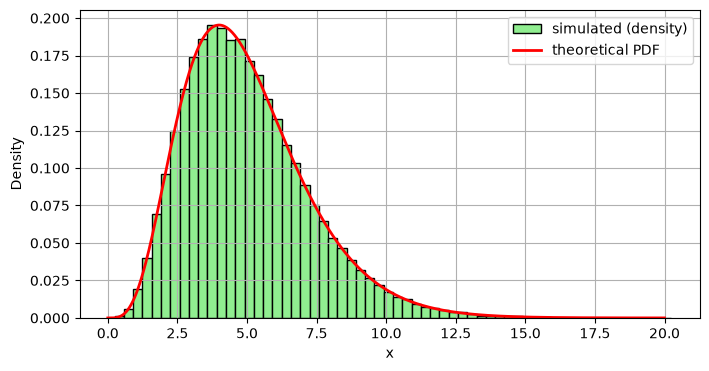

In [6]:
sample = rng.gamma(shape=a2, scale=1 / b2, size=100_000)
print(f"mean: sample {sample.mean():.4f}  theory {a2 / b2:.4f}")
print(f"var : sample {sample.var():.4f}  theory {a2 / b2**2:.4f}")

plt.figure(figsize=(8, 4))
plt.hist(sample, bins=60, density=True, color="lightgreen", edgecolor="black", label="simulated (density)")
plt.plot(x, stats.gamma.pdf(x, a2, scale=1 / b2), "r-", linewidth=2, label="theoretical PDF")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* Always translate rate to scale (`scale = 1/beta`) when calling scipy or numpy.
* For integer $\alpha$ the gamma is the waiting time for the $\alpha$-th event of a Poisson process.
* Mean $\alpha/\beta$ and variance $\alpha/\beta^2$ match the simulation.